# UTS Machine Learning: Klasifikasi Jenis Beras dengan KNN

| | |
|---|---|
| **Nama** | Paskalis Fanjaya Datul
| **NIM** | 2301010636
| **Kelas** |  XX |
| **Mata kuliah** | Machine Learning, Prodi Informatika |
| **Dosen** | Dr. I Gede Totok Suryawan, S.Kom., M.T. |
| **Jalur** | A: Klasifikasi |
| **Algoritma** | K-Nearest Neighbors (KNN), dibandingkan dengan baseline `DummyClassifier` |
| **Dataset** | Rice Type Classification (Kaggle)

---
##  Persiapan: Import Library dan SEED


1. **Import library**: pandas dan numpy untuk olah data, matplotlib untuk grafik, dan scikit-learn untuk modelnya (`train_test_split`, `StratifiedKFold`, `Pipeline`, `StandardScaler`, `KNeighborsClassifier`, `DummyClassifier`, dan metrik evaluasi).
2. **`SEED = 636`**: ini tiga digit terakhir NIM saya.


In [ ]:
# 0. Import library, SEED, dan pengaturan tampilan
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# SEED = tiga digit terakhir NIM.
SEED = 636

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# Palet warna grafik: Kelas 0 = biru, Kelas 1 = oranye (dipakai konsisten di semua grafik)
WARNA = {0: "#2a78d6", 1: "#eb6834"}
NETRAL = "#8a8985"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#d03b3b"])   # biru - abu - merah (korelasi)
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])   # biru muda -> tua (jumlah)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": "#c9c8c3", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10, "font.size": 10,
    "figure.dpi": 110, "legend.frameon": False,
})

print("SEED yang dipakai :", SEED)
print("pandas", pd.__version__, "| numpy", np.__version__)


SEED yang dipakai : 636
pandas 2.2.3 | numpy 2.4.6


---
# 1. Pemahaman Masalah dan Data


### 1.1 Latar belakang masalah, tujuan analisis, dan siapa penggunanya

**Latar belakang.** Beras itu salah satu komoditas pertanian terpenting di Indonesia. Di penggilingan, pengepul, atau koperasi tani, salah satu pekerjaan rutin adalah memastikan **jenis beras** dalam satu lot itu seragam atau tidak, karena jenis yang berbeda harganya bisa berbeda dan kalau tercampur, mutunya turun. Selama ini pengecekannya banyak dilakukan manual pakai mata: lambat, melelahkan, dan hasilnya bisa beda-beda tergantung siapa yang menilai (subjektif).

Dataset yang saya pakai berisi **hasil pengukuran bentuk dan ukuran butir beras** (luas, panjang, lebar, keliling, tingkat kebulatan, dan seterusnya). Nama fiturnya (misalnya `ConvexArea` dan `Extent`) kelihatannya dari pengolahan citra (foto) tiap butir.

**Tujuan analisis:** membangun model klasifikasi biner (2 kelas) memakai **KNN**, lalu membuktikan lewat angka bahwa model ini **lebih baik daripada baseline** (tebakan asal) dan tidak overfitting.

**Siapa yang memakai hasilnya:** Petani, Pengelola penggilingan, pengepul, koperasi tani, Petugas pengendali mutu (QC)

**Keputusan yang terbantu:** Apakah satu lot berasnya seragam atau tercampur jenis lain, jadi bisa menentukan harga dan cara pengelompokan, dan Butir mana yang bisa dilewatkan otomatis dan mana yang perlu dicek manual




### 1.2 Sumber data

| Item | Keterangan |
|---|---|
| **Judul dataset** | Rice Type Classification |
| **Link sumber** | https://www.kaggle.com/datasets/mssmartypants/rice-type-classification |
| **Tanggal akses** | 24 November 2026 |
| **Nama file** | `riceClassification.csv` |
| **Pemilik / pembuat dataset** | MsSmartyPants |
| **Lisensi** | Berkas data © Penulis Asli |

### 1.3 Kenapa saya memilih Jalur A (Klasifikasi)?


 **A. Klasifikasi** punya target berupa **kategori** Ada kolom `Class` yang isinya hanya 0 atau 1 (dua kategori jenis beras)


Jadi alasannya: **targetnya kategori dan labelnya sudah tersedia**, sehingga Jalur A (klasifikasi, *supervised learning*) adalah satu-satunya yang nyambung dengan Syarat ukuran dataset juga terpenuhi: **18.185 baris** (minimal 200) dan **10 fitur** numerik (minimal 4).

### 1.5 Tabel deskripsi kolom

Dataset punya **12 kolom**: 1 kolom `id`, 10 kolom fitur, dan 1 kolom target.
| Nama kolom | Tipe | Arti | Satuan |
|---|---|---|---|
| `id` | int64 | Nomor urut baris. Hanya penanda baris, **bukan** ciri fisik butir beras | tanpa satuan |
| `Area` | int64 | Luas butir: banyaknya piksel di dalam batas butir | piksel (px²) † |
| `MajorAxisLength` | float64 | Panjang sumbu utama, yaitu sisi terpanjang dari elips yang pas dengan bentuk butir (kira-kira **panjang** butir) | piksel † |
| `MinorAxisLength` | float64 | Panjang sumbu pendek elips tadi (kira-kira **lebar** butir) | piksel † |
| `Eccentricity` | float64 | Tingkat kelonjongan elips. Mendekati 0 berarti bulat, mendekati 1 berarti makin lonjong | tanpa satuan (0 sampai 1) |
| `ConvexArea` | int64 | Luas "cangkang cembung" terkecil yang membungkus butir | piksel (px²) † |
| `EquivDiameter` | float64 | Diameter lingkaran yang luasnya sama dengan `Area` (rumus: akar dari 4 × Area / π) | piksel † |
| `Extent` | float64 | Perbandingan luas butir terhadap luas kotak pembatasnya (bounding box) | rasio (0 sampai 1) |
| `Perimeter` | float64 | Keliling butir | piksel † |
| `Roundness` | float64 | Tingkat kebulatan = 4π × Area / Perimeter². Nilai 1 berarti lingkaran sempurna | rasio (0 sampai 1) |
| `AspectRation` | float64 | Rasio panjang : lebar butir = MajorAxisLength / MinorAxisLength. *(Nama kolom aslinya memang typo "Ration", saya biarkan apa adanya supaya cocok dengan file sumber.)* | rasio |
| `Class` | int64 | **Target**: kelas atau jenis beras, nilainya 0 atau 1 | kategori |

† *Satuan piksel adalah asumsi saya, karena fitur ini hasil pengolahan citra dan sumber datanya tidak mencantumkan satuan fisik (mm atau cm). Konsekuensinya: angka-angka ini hanya bisa dibandingkan kalau foto diambil dengan kamera dan jarak yang sama.*

### 1.4 Kenapa saya memilih algoritma KNN?

 Alasan saya memilihnya:

1. **Cocok dengan bentuk datanya.** Semua fitur numerik kontinu, dan dari eksplorasi nanti (Grafik 5) kelihatan butir-butir sekelas **mengumpul berdekatan**. Itu persis kondisi yang disukai KNN.

2. **Tuning-nya sederhana.** Parameter utamanya cuma satu, yaitu **k**, dan bisa dipilih dengan 5-fold cross-validation seperti diminta soal.


Kelemahan KNN :**sensitif terhadap skala fitur**, jadi wajib di-*scaling*; KNN juga bisa terpengaruh **fitur yang redundan**; dan prediksinya melambat kalau datanya sangat besar.

### 1.6 Membaca dataset

Sel ini membaca file CSV ke dalam DataFrame `df`.

In [ ]:
# 1.6 Baca dataset dan intip 5 baris pertama
LOKASI = ["../data/riceClassification.csv", "data/riceClassification.csv", "riceClassification.csv"]
path = next((p for p in LOKASI if os.path.exists(p)), None)

if path is None:
    from google.colab import files
    files.upload()
    path = "riceClassification.csv"

df = pd.read_csv(path)
print("File dibaca dari     :", path)
print("Jumlah baris x kolom :", df.shape)
df.head()


File dibaca dari     : riceClassification.csv
Jumlah baris x kolom : (18185, 12)


,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.2293,64.0128,0.7199,4677,76.0045,0.6575,273.0850,0.7645,1.4408,1
1,2,2872,74.6919,51.4005,0.7256,3015,60.4710,0.7130,208.3170,0.8317,1.4531,1
2,3,3048,76.2932,52.0435,0.7312,3132,62.2963,0.7592,210.0120,0.8684,1.4660,1
3,4,3073,77.0336,51.9285,0.7386,3157,62.5513,0.7835,210.6570,0.8702,1.4835,1
4,5,3693,85.1248,56.3740,0.7493,3802,68.5717,0.7694,230.3320,0.8747,1.5100,1


### 1.7 Struktur data dan ringkasan statistik



In [ ]:
# 1.7 Struktur data dan ringkasan statistik
df.info()
print()
display(df.describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB



,count,mean,std,min,25%,50%,75%,max
id,18185.0000,9093.0000,5249.7017,1.0000,4547.0000,9093.0000,13639.0000,18185.0000
Area,18185.0000,7036.4930,1467.1972,2522.0000,5962.0000,6660.0000,8423.0000,10210.0000
MajorAxisLength,18185.0000,151.6808,12.3764,74.1331,145.6759,153.8837,160.0562,183.2114
MinorAxisLength,18185.0000,59.8079,10.0617,34.4099,51.3932,55.7243,70.1566,82.5508
Eccentricity,18185.0000,0.9154,0.0306,0.6766,0.8916,0.9233,0.9414,0.9668
ConvexArea,18185.0000,7225.8179,1502.0066,2579.0000,6125.0000,6843.0000,8645.0000,11008.0000
EquivDiameter,18185.0000,94.1330,9.9063,56.6667,87.1267,92.0857,103.5591,114.0166
Extent,18185.0000,0.6167,0.1044,0.3832,0.5385,0.6012,0.6957,0.8866
Perimeter,18185.0000,351.6069,29.5006,197.0150,333.9900,353.0880,373.0030,508.5110
Roundness,18185.0000,0.7080,0.0673,0.1746,0.6510,0.7019,0.7693,0.9047


### 1.8 Keputusan saya (Tahap 1)

**Tahap 1**
- **1.1 sampai 1.5 (teks):** merumuskan masalah, tujuan, pengguna, sumber data, alasan memilih jalur dan algoritma, serta kamus kolom.
- **Sel 1.6 (kode):** membaca `riceClassification.csv`. **Hasilnya:** tabel berukuran **18.185 baris × 12 kolom** (`id`, 10 fitur ukuran dan bentuk, `Class`).
- **Sel 1.7 (kode):** `info()` dan `describe()`. **Hasilnya:** 4 kolom bertipe integer dan 8 kolom bertipe desimal, **semua numerik**, dan di setiap kolom terisi 18.185 nilai (artinya tidak ada yang kosong). Skala antar kolom beda jauh: `Area` berkisar 2.522 sampai 10.210, sedangkan `Eccentricity` hanya 0,68 sampai 0,97.

**Keputusan yang saya ambil dan alasannya**
1. **Jalur A (Klasifikasi)**, karena target `Class` berupa kategori (0 atau 1) yang sudah berlabel.
2. **Algoritma KNN** (satu algoritma saja, dibandingkan dengan baseline DummyClassifier), karena fiturnya numerik kontinu, kelasnya mengumpul berdekatan dan tuning-nya cukup satu parameter (k).
3. **Target = `Class`; fitur = 10 kolom ukuran dan bentuk.** Kolom `id` **tidak langsung buang**
4. **Metrik utama:** akurasi, presisi, recall, dan F1, dengan **Kelas 1 sebagai kelas positif**. Akurasi saja tidak cukup karena kelasnya tidak 100% seimbang (54,9% berbanding 45,1%).




---
# 2. Eksplorasi dan Visualisasi Data


### 2.1 Menyiapkan daftar fitur dan label kelas



In [ ]:
# 2.1 Siapkan daftar fitur dan label kelas (dipakai di semua grafik)
FITUR = [c for c in df.columns if c not in ["id", "Class"]]   # 10 fitur ukuran dan bentuk butir
NAMA_KELAS = {0: "Kelas 0", 1: "Kelas 1"}
print("Jumlah fitur :", len(FITUR))
print("Daftar fitur :", FITUR)


Jumlah fitur : 10
Daftar fitur : ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation']


### 2.2 Grafik 1: Distribusi target (Class)

**Kenapa saya memilih bar chart?** Karena `Class` itu data **kategori** (cuma ada dua nilai, 0 dan 1) dan yang ingin saya lihat cuma satu hal: *berapa butir di tiap kelas*.

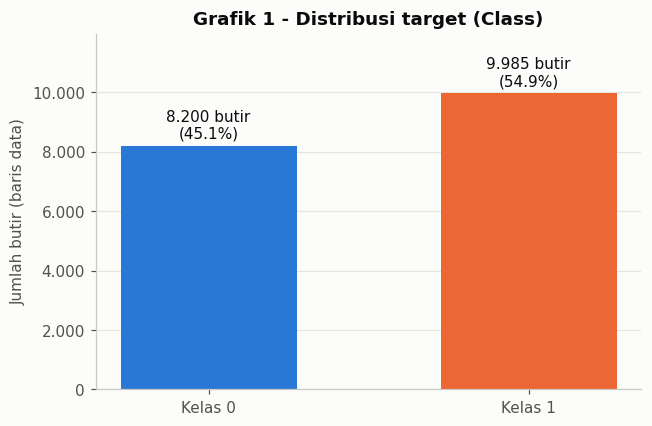

In [ ]:
# 2.2 Grafik 1: distribusi target (Class)
hitung = df["Class"].value_counts().sort_index()
persen = hitung / hitung.sum() * 100

fig, ax = plt.subplots(figsize=(6.4, 4.2))
bars = ax.bar([NAMA_KELAS[k] for k in hitung.index], hitung.values,
              color=[WARNA[k] for k in hitung.index], width=0.55)
for b, n, p in zip(bars, hitung.values, persen.values):
    teks = f"{n:,} butir\n({p:.1f}%)".replace(",", ".")
    ax.text(b.get_x() + b.get_width() / 2, n + 150, teks, ha="center", va="bottom", color=INK, fontsize=10)
ax.set_ylim(0, hitung.max() * 1.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):,}".replace(",", "."))
ax.set_ylabel("Jumlah butir (baris data)")
ax.set_title("Grafik 1 - Distribusi target (Class)")
ax.grid(axis="x", visible=False)
plt.show()


#### 2.2 Isi dan interpretasi Grafik 1

**Isi grafik.** Sumbu X berisi dua kelas, sumbu Y jumlah butir (baris data). Batang **biru (Kelas 0) = 8.200 butir (45,1%)** dan batang **oranye (Kelas 1) = 9.985 butir (54,9%)**. Total 18.185 butir.

**Interpretasi.**
- Selisih kedua kelas 1.785 butir, atau perbandingan sekitar **1,22 : 1**. Jadi kelasnya **hampir seimbang**, tidak perlu oversampling atau undersampling.
- Tapi ada konsekuensi: model "bodoh" yang selalu menebak Kelas 1 sudah otomatis benar **54,9%**. Angka ini jadi **patokan minimal (baseline)** yang harus dilampaui model saya.
- Karena sedikit timpang, saya akan memakai **`stratify=y`** saat membagi data (supaya proporsi kelas di data latih dan uji sama) dan tidak hanya melihat akurasi, tapi juga presisi, recall, dan F1.

### 2.3 Grafik 2: Distribusi 10 fitur (histogram)



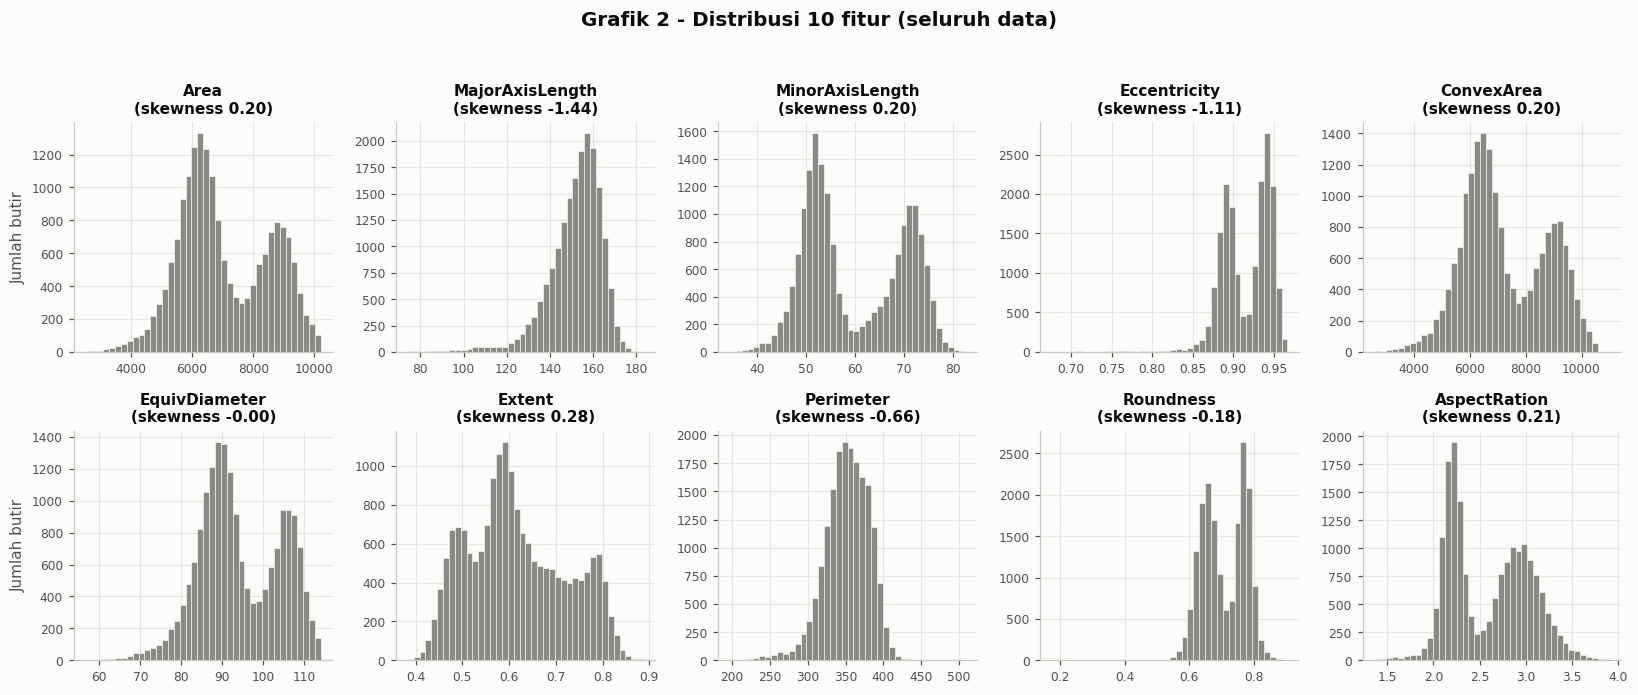

In [ ]:
# 2.3 Grafik 2: histogram distribusi 10 fitur
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for ax, f in zip(axes.ravel(), FITUR):
    ax.hist(df[f], bins=40, color=NETRAL, edgecolor=SURFACE, linewidth=0.4)
    ax.set_title(f"{f}\n(skewness {df[f].skew():.2f})", fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Jumlah butir")
fig.suptitle("Grafik 2 - Distribusi 10 fitur (seluruh data)", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


#### 2.3 Isi dan interpretasi Grafik 2

**Isi grafik.** Ada 10 panel (satu per fitur). Sumbu X adalah nilai fitur, sumbu Y adalah banyaknya butir di rentang nilai itu. Beberapa angka penting dari judul panel: skewness `MajorAxisLength` = -1,44, `Eccentricity` = -1,11, `Perimeter` = -0,66, sedangkan `Area`, `MinorAxisLength`, `ConvexArea`, `AspectRation` kira-kira 0,20 (hampir simetris).

**Interpretasi.**
1. **Tujuh dari sepuluh fitur punya dua "gunung"** (dua puncak): `Area`, `MinorAxisLength`, `Eccentricity`, `ConvexArea`, `EquivDiameter`, `Roundness`, dan `AspectRation`. Contohnya `MinorAxisLength` punya puncak di sekitar 52 dan 72, sedangkan `AspectRation` di sekitar 2,2 dan 2,9. Dua puncak ini pertanda kuat bahwa di dalam data ada **dua kelompok butir** yang berbeda. Dugaan saya kelompok itu adalah dua kelas, dan akan saya cek di Grafik 3.
2. **`MajorAxisLength` dan `Perimeter` hanya punya satu puncak dengan ekor panjang ke kiri** (skewness negatif). Artinya ada sebagian butir yang jauh lebih pendek atau kecil daripada kebanyakan. Mereka **calon outlier** yang akan saya periksa pakai aturan IQR di Tahap 3.
3. **Skala antar fitur sangat berbeda.** `Area` bernilai ribuan (2.522 sampai 10.210), `Perimeter` ratusan (197 sampai 509), sedangkan `Eccentricity`, `Roundness`, dan `Extent` cuma di sekitar 0 sampai 1. Karena KNN menghitung **jarak**, fitur dengan angka besar akan "mendominasi" kalau tidak diseragamkan. Kesimpulannya: **scaling wajib**.
4. `Extent` sebarannya lebar dan tidak punya dua puncak yang jelas, jadi kemungkinan kurang membedakan kelas (nanti dilihat lagi di Grafik 3 dan 4).

### 2.4 Grafik 3: Boxplot fitur untuk tiap kelas (hubungan fitur dengan target)



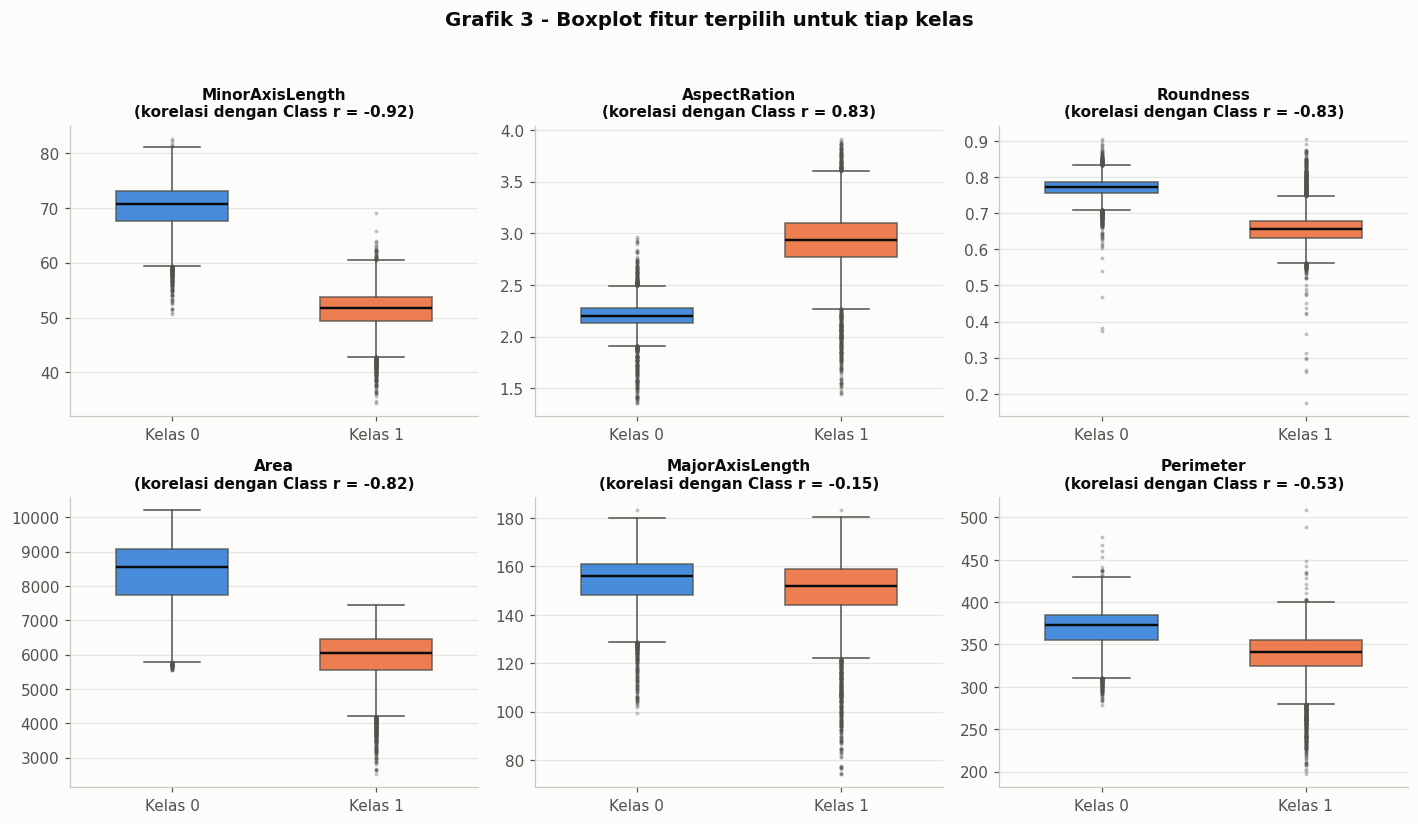

In [ ]:
# 2.4 Grafik 3: boxplot fitur per kelas (hubungan fitur dengan target + outlier)
fitur_box = ["MinorAxisLength", "AspectRation", "Roundness", "Area", "MajorAxisLength", "Perimeter"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7.6))
for ax, f in zip(axes.ravel(), fitur_box):
    data = [df.loc[df["Class"] == k, f] for k in (0, 1)]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    medianprops=dict(color=INK, linewidth=1.6),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK2,
                                    markeredgecolor="none", alpha=0.35))
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(WARNA[k]); patch.set_alpha(0.85); patch.set_edgecolor(INK2)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Kelas 0", "Kelas 1"])
    r = df[f].corr(df["Class"])
    ax.set_title(f"{f}\n(korelasi dengan Class r = {r:.2f})", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Grafik 3 - Boxplot fitur terpilih untuk tiap kelas", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


#### 2.4 Isi dan interpretasi Grafik 3

**Isi grafik.** Ada 6 panel. Di tiap panel, sumbu X adalah kelas (kotak biru = Kelas 0, oranye = Kelas 1) dan sumbu Y adalah nilai fitur. Angka mediannya (Kelas 0 berbanding Kelas 1):

| Fitur | Median Kelas 0 | Median Kelas 1 | Kotak (IQR) kedua kelas |
|---|---|---|---|
| `MinorAxisLength` | 70,7 | 51,7 | **terpisah jelas** (67,6 sampai 73,1 vs 49,4 sampai 53,8) |
| `AspectRation` | 2,20 | 2,94 | **terpisah jelas** (2,13 sampai 2,28 vs 2,77 sampai 3,10) |
| `Roundness` | 0,771 | 0,655 | **terpisah jelas** |
| `Area` | 8.556 | 6.057 | **terpisah jelas** |
| `Perimeter` | 373,5 | 341,3 | hampir bersentuhan (355,3 vs 354,7) |
| `MajorAxisLength` | 155,9 | 152,0 | **saling tumpang tindih** |

**Interpretasi.**
1. **Dugaan dari Grafik 2 terbukti:** dua puncak tadi adalah dua kelas. Misalnya median `MinorAxisLength` kedua kelas (70,7 dan 51,7) cocok dengan dua puncak di sekitar 72 dan 52 pada Grafik 2.
2. **Gambaran fisik kedua kelas:** butir **Kelas 0 lebih lebar, lebih bulat, dan lebih luas**; butir **Kelas 1 lebih ramping dan memanjang** (rasio panjang : lebar tinggi, lebar kecil). Yang menarik, **panjangnya (`MajorAxisLength`) hampir sama** di kedua kelas. Jadi yang membedakan jenisnya terutama **lebar dan kebulatan**, bukan panjang.
3. Empat fitur teratas punya kotak yang **tidak saling tumpang tindih**, artinya kelas-kelas ini **mudah dipisahkan**. Sebaliknya `MajorAxisLength` kotaknya menumpuk, jadi fitur ini lemah sebagai pembeda.
4. **Outlier (titik-titik) muncul di semua panel.** Di `MajorAxisLength` dan `Perimeter` kebanyakan berupa butir yang lebih pendek atau kecil, dan sebagian besar milik Kelas 1. Catatan: titik outlier di boxplot ditentukan **per kelas** (tiap kotak punya IQR sendiri).

### 2.5 Grafik 4: Heatmap korelasi antar fitur dan terhadap Class


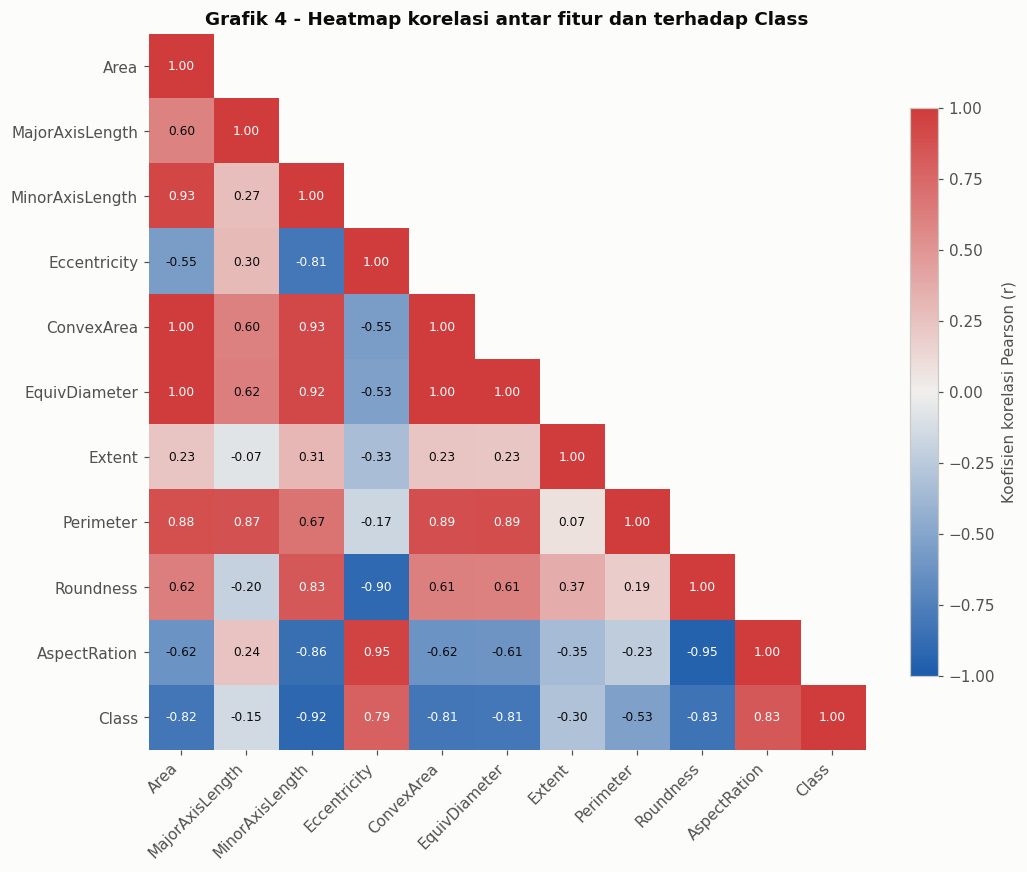

In [ ]:
# 2.5 Grafik 4: heatmap korelasi antar fitur dan terhadap Class
kolom_kor = FITUR + ["Class"]
kor = df[kolom_kor].corr()
n = len(kolom_kor)
kor_tampil = kor.mask(np.triu(np.ones((n, n), dtype=bool), k=1))   # tampilkan segitiga bawah saja

fig, ax = plt.subplots(figsize=(10.5, 8.6))
im = ax.imshow(kor_tampil.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(kolom_kor, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(kolom_kor)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
for i in range(n):
    for j in range(i + 1):
        v = kor.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.7 else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.78)
cbar.set_label("Koefisien korelasi Pearson (r)")
ax.set_title("Grafik 4 - Heatmap korelasi antar fitur dan terhadap Class")
plt.show()


#### 2.5 Isi dan interpretasi Grafik 4

**Isi grafik.** Tiap kotak berisi koefisien korelasi (r) antara dua kolom, dari -1 sampai +1. Baris paling bawah (`Class`) menunjukkan hubungan tiap fitur dengan target:

| Fitur | r dengan Class | Fitur | r dengan Class |
|---|---|---|---|
| `MinorAxisLength` | -0,92 (terkuat) | `Eccentricity` | 0,79 |
| `AspectRation` | 0,83 | `Perimeter` | -0,53 |
| `Roundness` | -0,83 | `Extent` | -0,30 |
| `Area` | -0,82 | `MajorAxisLength` | -0,15 (terlemah) |
| `ConvexArea` / `EquivDiameter` | -0,81 / -0,81 | | |

Antar fitur: `Area`-`ConvexArea` = 1,00, `Area`-`EquivDiameter` = 1,00, `ConvexArea`-`EquivDiameter` = 1,00, `Eccentricity`-`AspectRation` = 0,95, `Roundness`-`AspectRation` = -0,95, `Roundness`-`Eccentricity` = -0,90.

**Interpretasi.**
1. **Hampir semua fitur berhubungan kuat dengan target** (tujuh fitur punya |r| di atas 0,78). Ini kabar baik: peluang model bisa akurat tinggi.
2. **Arah tanda cocok dengan Grafik 3.** Korelasi negatif (biru) pada `MinorAxisLength`, `Area`, dan `Roundness` berarti makin besar nilainya, makin condong ke Kelas 0. Korelasi positif (merah) pada `AspectRation` dan `Eccentricity` berarti makin lonjong, makin condong ke Kelas 1.
3. **Ada fitur yang praktis kembar.** `Area`, `ConvexArea`, dan `EquivDiameter` korelasinya mendekati 1,00, jadi ketiganya membawa informasi "ukuran" yang sama. `Eccentricity`, `AspectRation`, dan `Roundness` juga saling berkorelasi sangat kuat (0,90 sampai 0,95). Artinya 10 fitur ini sebenarnya **bukan 10 informasi yang benar-benar berbeda**. Di sel 3.6 saya akan buktikan bahwa sebagian memang turunan dari fitur lain.
4. `MajorAxisLength` nyaris tidak berhubungan linear dengan target (r = -0,15), konsisten dengan Grafik 3. Tapi saya **tidak langsung membuangnya**: korelasi rendah belum tentu tidak berguna kalau dipakai bersama fitur lain (misalnya lewat rasio panjang : lebar).
5. **Dampaknya buat algoritma:** fitur kembar membuat "ukuran" terhitung berkali-kali dalam jarak KNN

### 2.6 Grafik 5: Scatter plot MinorAxisLength vs AspectRation per kelas



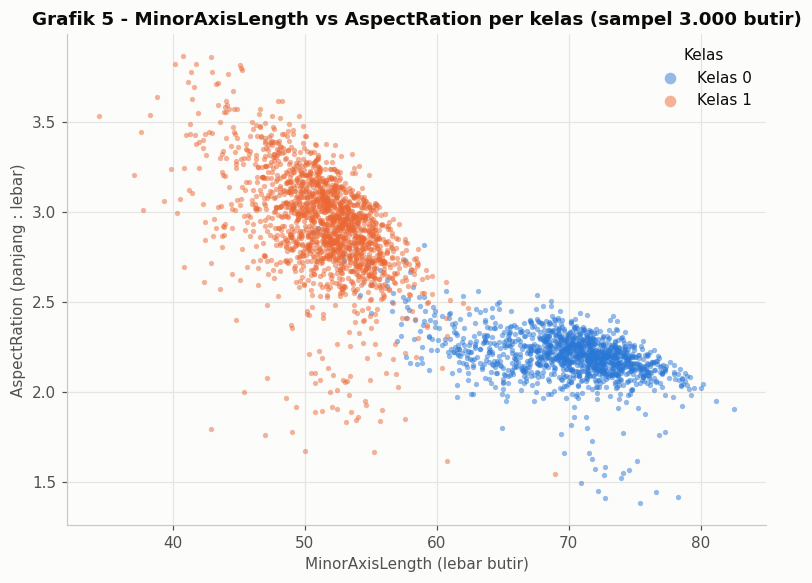

In [ ]:
# 2.6 Grafik 5: scatter plot dua fitur terkuat, diwarnai per kelas
contoh = df.sample(n=3000, random_state=SEED)   # 3000 titik acak supaya grafik tidak penuh sesak

fig, ax = plt.subplots(figsize=(8.2, 5.8))
for k in (0, 1):
    d = contoh[contoh["Class"] == k]
    ax.scatter(d["MinorAxisLength"], d["AspectRation"], s=12, color=WARNA[k],
               alpha=0.5, linewidths=0, label=NAMA_KELAS[k])
ax.set_xlabel("MinorAxisLength (lebar butir)")
ax.set_ylabel("AspectRation (panjang : lebar)")
ax.set_title("Grafik 5 - MinorAxisLength vs AspectRation per kelas (sampel 3.000 butir)")
ax.legend(title="Kelas", loc="upper right", markerscale=2.2)
plt.show()


#### 2.6 Isi dan interpretasi Grafik 5

**Isi grafik.** Sumbu X adalah lebar butir (`MinorAxisLength`), sumbu Y adalah rasio panjang : lebar (`AspectRation`). Titik **oranye (Kelas 1)** mengumpul di **kiri-atas**: setengah butir Kelas 1 punya lebar 49,4 sampai 53,8 dan rasio 2,77 sampai 3,10. Titik **biru (Kelas 0)** mengumpul di **kanan-bawah**: setengah butir Kelas 0 punya lebar 67,6 sampai 73,1 dan rasio 2,13 sampai 2,28.

**Interpretasi.**
1. **Dua gerombol terlihat jelas terpisah.** Daerah yang bercampur cuma sempit, kira-kira di tengah (lebar sekitar 57 sampai 62). Untuk butir yang jatuh di tengah salah satu gerombol, hampir semua tetangga terdekatnya hampir pasti sekelas.
2. **Kesalahan akan menumpuk di dua tempat:** di zona campur yang sempit itu, dan pada **titik-titik "nyasar"** (beberapa oranye di rasio rendah dan beberapa biru di rasio sekitar 1,4 sampai 1,7). Titik nyasar ini yang tadi terlihat sebagai titik-titik outlier di boxplot.


### 2.7 Keputusan saya (Tahap 2)

**Tahap 2**
- **Sel 2.1:** menyiapkan daftar 10 fitur (`FITUR`) dan label kelas.
- **Grafik 1 (bar chart):** target terdiri dari 8.200 butir Kelas 0 (45,1%) dan 9.985 butir Kelas 1 (54,9%), jadi hampir seimbang.
- **Grafik 2 (histogram 10 fitur):** tujuh fitur berbentuk dua puncak; `MajorAxisLength`, `Eccentricity`, dan `Perimeter` miring ke kiri; skala antar fitur sangat berbeda (`Area` ribuan, `Eccentricity` di bawah 1).
- **Grafik 3 (boxplot per kelas):** empat fitur (`MinorAxisLength`, `AspectRation`, `Roundness`, `Area`) kotaknya terpisah jelas antar kelas; `MajorAxisLength` menumpuk; titik outlier terlihat di keenam panel (dihitung per kelas).
- **Grafik 4 (heatmap korelasi):** 7 fitur berkorelasi kuat dengan target (|r| di atas 0,78), terkuat `MinorAxisLength` (r = -0,92); `Area`, `ConvexArea`, `EquivDiameter` praktis kembar (r mendekati 1,00).
- **Grafik 5 (scatter plot):** dua gerombol kelas terpisah jelas dengan zona campur yang sempit.

**Keputusan yang saya ambil dan alasannya**
1. **Pakai `stratify=y` saat bagi data dan laporkan presisi, recall, F1 (bukan cuma akurasi)**, karena kelas tidak 100% seimbang (Grafik 1). Resampling tidak perlu karena selisihnya kecil.
2. **Scaling wajib** (`StandardScaler`), karena skala fitur beda jauh (Grafik 2) dan KNN berbasis jarak.
3. **KNN saya pertahankan sebagai pilihan algoritma**, karena kelas-kelasnya mengumpul berdekatan (Grafik 5) dan terpisah jelas pada fitur-fitur utama (Grafik 3).
4. **Semua 10 fitur belum ada yang dibuang** saat ini. `MajorAxisLength` lemah secara korelasi, tapi korelasi linear rendah belum berarti tidak berguna bersama fitur lain.
5. **Outlier akan dihitung dengan aturan IQR di Tahap 3** (hanya dari data latih), lalu diputuskan dipertahankan atau dibuang berdasarkan bukti.


---
# 3. Pra-pemrosesan Data




### 3.1 Cek missing value



In [ ]:
# 3.1 Cek missing value
ringkas = pd.DataFrame({
    "tipe_data": df.dtypes.astype(str),
    "jumlah_missing": df.isna().sum(),
    "persen_missing": df.isna().mean() * 100,
})
display(ringkas)
print("Total missing value di seluruh tabel :", int(df.isna().sum().sum()))


,tipe_data,jumlah_missing,persen_missing
id,int64,0,0.0000
Area,int64,0,0.0000
MajorAxisLength,float64,0,0.0000
MinorAxisLength,float64,0,0.0000
Eccentricity,float64,0,0.0000
ConvexArea,int64,0,0.0000
EquivDiameter,float64,0,0.0000
Extent,float64,0,0.0000
Perimeter,float64,0,0.0000
Roundness,float64,0,0.0000


Total missing value di seluruh tabel : 0


### 3.2 Cek duplikat, label kategori (dan kebutuhan encoding), serta nilai yang tidak masuk akal


In [ ]:
# 3.2 Cek duplikat, label kategori, dan nilai yang tidak masuk akal
dup_penuh = int(df.duplicated().sum())
dup_tanpa_id = int(df.drop(columns="id").duplicated().sum())
kolom_teks = df.select_dtypes(exclude="number").columns.tolist()   # kolom non-angka (teks/kategori)
nilai_tak_wajar = int((df[FITUR] <= 0).sum().sum())

print("Baris duplikat (semua kolom)            :", dup_penuh)
print("Baris duplikat (di luar kolom id)       :", dup_tanpa_id)
print("Nilai unik di kolom Class               :", sorted(df["Class"].unique().tolist()))
print("Kolom bertipe teks/kategori             :", kolom_teks if kolom_teks else "tidak ada")
print("Nilai <= 0 di fitur ukuran (tak wajar)  :", nilai_tak_wajar)


Baris duplikat (semua kolom)            : 0
Baris duplikat (di luar kolom id)       : 0
Nilai unik di kolom Class               : [0, 1]
Kolom bertipe teks/kategori             : tidak ada
Nilai <= 0 di fitur ukuran (tak wajar)  : 0


### 3.3 Membagi data latih dan data uji (stratify + SEED)



In [ ]:
# 3.3 Pisahkan fitur dan target, lalu bagi data latih-uji (stratify + SEED)
X_all = df.drop(columns="Class")   # id sengaja belum dibuang, mau dicek dulu di sel berikutnya
y = df["Class"]

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, stratify=y, random_state=SEED)

# Cross-validation 5-fold, dipakai di semua tahap berikutnya
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

tabel_split = pd.DataFrame({
    "jumlah_baris": [len(df), len(y_train), len(y_test)],
    "persen_kelas_1": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["Seluruh data", "Data latih (80%)", "Data uji (20%)"])
display(tabel_split)


,jumlah_baris,persen_kelas_1
Seluruh data,18185,54.9079
Data latih (80%),14548,54.9079
Data uji (20%),3637,54.9079


### 3.4 Memeriksa kolom `id`: apakah dia "membocorkan" jawaban?

In [ ]:
# 3.4 Cek kolom id: apakah ia "bocorin" jawaban? (dicek di DATA LATIH )
pohon = DecisionTreeClassifier(max_depth=1, random_state=SEED)   # pohon 1 level = satu aturan "kalau nilai < batas"

skor_id = cross_val_score(pohon, X_train_all[["id"]], y_train, cv=cv).mean()
skor_minor = cross_val_score(pohon, X_train_all[["MinorAxisLength"]], y_train, cv=cv).mean()

print("Akurasi CV pakai 1 kolom 'id' saja              :", round(skor_id, 4))
print("Akurasi CV pakai 1 kolom 'MinorAxisLength' saja :", round(skor_minor, 4))
print("Korelasi id dengan Class (data latih)           :", round(X_train_all["id"].corr(y_train), 4))
print()
display(X_train_all["id"].groupby(y_train).agg(["min", "median", "max"]).rename_axis("Class"))

# id dibuang dari fitur
X_train = X_train_all.drop(columns="id")
X_test = X_test_all.drop(columns="id")
print("Bentuk X_train :", X_train.shape, "| X_test :", X_test.shape)


Akurasi CV pakai 1 kolom 'id' saja              : 0.9247
Akurasi CV pakai 1 kolom 'MinorAxisLength' saja : 0.985
Korelasi id dengan Class (data latih)           : -0.8084



,min,median,max
Class,,,
0,2491,14077.5000,18185
1,1,5121.5000,11516


Bentuk X_train : (14548, 10) | X_test : (3637, 10)


### 3.5 Deteksi outlier dengan aturan IQR (dihitung dari data latih)



In [ ]:
# 3.5 Deteksi outlier dengan aturan IQR (batas dihitung dari DATA LATIH)
baris = []
mask_any = pd.Series(False, index=X_train.index)
for f in FITUR:
    q1, q3 = X_train[f].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (X_train[f] < bawah) | (X_train[f] > atas)
    mask_any |= m
    baris.append({
        "fitur": f, "batas_bawah": bawah, "batas_atas": atas,
        "jumlah_outlier": int(m.sum()), "persen_outlier": m.mean() * 100,
        "persen_kelas1_di_outlier": y_train[m].mean() * 100 if m.sum() > 0 else np.nan,
    })
tabel_outlier = pd.DataFrame(baris).set_index("fitur")
display(tabel_outlier)

n_any = int(mask_any.sum())
print(f"Baris dengan minimal 1 outlier : {n_any} dari {len(X_train)} ({n_any / len(X_train) * 100:.2f}%)")
print(f"Porsi Kelas 1 di baris-baris outlier : {y_train[mask_any].mean() * 100:.1f}%  (porsi Kelas 1 di seluruh data latih: {y_train.mean() * 100:.1f}%)")


,batas_bawah,batas_atas,jumlah_outlier,persen_outlier,persen_kelas1_di_outlier
fitur,,,,,
Area,2263.5000,12123.5000,0,0.0000,NaN
MajorAxisLength,123.9570,181.7162,421,2.8939,78.6223
MinorAxisLength,23.2583,98.3032,0,0.0000,NaN
Eccentricity,0.8170,1.0159,110,0.7561,22.7273
ConvexArea,2337.2500,12435.2500,0,0.0000,NaN
EquivDiameter,62.4320,128.2649,12,0.0825,100.0000
Extent,0.3007,0.9336,0,0.0000,NaN
Perimeter,275.1134,431.8564,248,1.7047,96.7742
Roundness,0.4728,0.9471,11,0.0756,81.8182


Baris dengan minimal 1 outlier : 455 dari 14548 (3.13%)
Porsi Kelas 1 di baris-baris outlier : 74.9%  (porsi Kelas 1 di seluruh data latih: 54.9%)


### 3.6 Memeriksa fitur turunan (redundan) dan pasangan fitur yang berkorelasi sangat tinggi



In [ ]:
# 3.6 Cek fitur yang ternyata turunan dari fitur lain (redundan)
rumus = {
    "EquivDiameter = sqrt(4 x Area / pi)":        np.sqrt(4 * X_train["Area"] / np.pi) - X_train["EquivDiameter"],
    "AspectRation = MajorAxis / MinorAxis":       X_train["MajorAxisLength"] / X_train["MinorAxisLength"] - X_train["AspectRation"],
    "Roundness = 4 x pi x Area / Perimeter^2":    4 * np.pi * X_train["Area"] / X_train["Perimeter"] ** 2 - X_train["Roundness"],
    "Eccentricity = sqrt(1 - (Minor/Major)^2)":   np.sqrt(1 - (X_train["MinorAxisLength"] / X_train["MajorAxisLength"]) ** 2) - X_train["Eccentricity"],
}
for nama, selisih in rumus.items():
    print(f"{nama:<45} selisih terbesar = {selisih.abs().max():.5f}")

kor_abs = X_train.corr().abs()
pasangan = [(a, b, kor_abs.loc[a, b]) for i, a in enumerate(kor_abs.columns) for b in kor_abs.columns[i + 1:] if kor_abs.loc[a, b] >= 0.95]
print()
display(pd.DataFrame(pasangan, columns=["fitur_1", "fitur_2", "abs_korelasi"]).sort_values("abs_korelasi", ascending=False).reset_index(drop=True))


EquivDiameter = sqrt(4 x Area / pi)           selisih terbesar = 0.00000
AspectRation = MajorAxis / MinorAxis          selisih terbesar = 0.00000
Roundness = 4 x pi x Area / Perimeter^2       selisih terbesar = 0.00000
Eccentricity = sqrt(1 - (Minor/Major)^2)      selisih terbesar = 0.00000



,fitur_1,fitur_2,abs_korelasi
0,Area,ConvexArea,0.9994
1,Area,EquivDiameter,0.9982
2,ConvexArea,EquivDiameter,0.9974
3,Eccentricity,AspectRation,0.9507


### 3.7 Uji cepat: perlukah scaling, dan perlukah membuang fitur redundan?



In [ ]:
# 3.7 Uji cepat: scaling dan fitur redundan (5-fold CV di data latih, k sementara = 5)
def cv_knn(scaler, kolom, k=5):
    langkah = ([("scaler", scaler)] if scaler is not None else []) + [("knn", KNeighborsClassifier(n_neighbors=k))]
    s = cross_val_score(Pipeline(langkah), X_train[kolom], y_train, cv=cv)
    return s.mean(), s.std()

tanpa_redundan = [f for f in FITUR if f not in ("ConvexArea", "EquivDiameter")]
skenario = [
    ("Tanpa scaling, semua fitur", None, FITUR),
    ("StandardScaler, semua fitur", StandardScaler(), FITUR),
    ("RobustScaler, semua fitur", RobustScaler(), FITUR),
    ("StandardScaler, tanpa ConvexArea & EquivDiameter", StandardScaler(), tanpa_redundan),
]
baris = []
for nama, sc, kolom in skenario:
    rata, sd = cv_knn(sc, kolom)
    baris.append({"skenario": nama, "jumlah_fitur": len(kolom), "akurasi_cv_rata2": rata, "std": sd})
hasil_uji_cepat = pd.DataFrame(baris).set_index("skenario")
display(hasil_uji_cepat)


,jumlah_fitur,akurasi_cv_rata2,std
skenario,,,
"Tanpa scaling, semua fitur",10,0.9821,0.0023
"StandardScaler, semua fitur",10,0.9880,0.0030
"RobustScaler, semua fitur",10,0.9885,0.0025
"StandardScaler, tanpa ConvexArea & EquivDiameter",8,0.9882,0.0031


### 3.8 Bukti bahwa scaler hanya belajar dari data latih



In [ ]:
# 3.8 Bukti: scaler hanya belajar dari data latih (data uji tidak ikut "ngintip")
scaler_demo = StandardScaler().fit(X_train)          # fit HANYA di data latih
Z_train = scaler_demo.transform(X_train)
Z_test = scaler_demo.transform(X_test)                # data uji cuma di-transform, tidak di-fit

bukti = pd.DataFrame({
    "rata2_latih_sebelum_scaling": scaler_demo.mean_,
    "rata2_latih_setelah_scaling": Z_train.mean(axis=0),
    "rata2_uji_setelah_scaling": Z_test.mean(axis=0),
}, index=FITUR)
display(bukti)


,rata2_latih_sebelum_scaling,rata2_latih_setelah_scaling,rata2_uji_setelah_scaling
Area,7038.4257,-0.0000,-0.0066
MajorAxisLength,151.6924,0.0000,-0.0047
MinorAxisLength,59.8202,0.0000,-0.0062
Eccentricity,0.9154,0.0000,0.0011
ConvexArea,7227.8374,-0.0000,-0.0067
EquivDiameter,94.1456,0.0000,-0.0064
Extent,0.6167,-0.0000,-0.0041
Perimeter,351.6470,0.0000,-0.0068
Roundness,0.7080,-0.0000,-0.0019
AspectRation,2.5988,-0.0000,0.0031


### 3.9 Keputusan saya (Tahap 3)

**tahap 3**

| Sel | Yang dikerjakan | Hasil |
|---|---|---|
| 3.1 | Cek missing value | **0 nilai kosong** di seluruh tabel |
| 3.2 | Cek duplikat, label, tipe kolom, nilai tak wajar | Duplikat: **0** (semua kolom) dan **0** (di luar `id`). Nilai unik `Class` = [0, 1]. Kolom teks: tidak ada. Nilai nol atau negatif: **0** |
| 3.3 | Bagi data 80:20, `stratify=y`, `SEED=636`, buat `cv` | **14.548 baris latih** dan **3.637 baris uji**; porsi Kelas 1 di seluruh data, data latih, dan data uji sama: **54,91%** |
| 3.4 | Periksa `id` di data latih | 1 aturan pakai `id` saja sudah **92,47%** akurasi CV (baseline 54,91%), korelasi `id` dengan `Class` = **-0,81**. Pembanding: `MinorAxisLength` saja **98,50%** |
| 3.5 | Outlier IQR di data latih | **455 dari 14.548 baris (3,13%)** punya minimal satu outlier. Terbanyak: `MajorAxisLength` (421 baris), `Perimeter` (248), `Eccentricity` (110). Porsi Kelas 1 di baris outlier **74,9%** (di seluruh data latih 54,9%) |
| 3.6 | Cek fitur turunan | Keempat rumus (`EquivDiameter`, `AspectRation`, `Roundness`, `Eccentricity`) **cocok persis** (selisih terbesar 0,00000). Ada **4 pasangan** fitur dengan korelasi mutlak minimal 0,95 |
| 3.7 | Uji cepat scaling dan fitur redundan (CV, k = 5) | Tanpa scaling **98,21%**; `StandardScaler` **98,80%**; `RobustScaler` **98,85%**; `StandardScaler` tanpa 2 fitur kembar **98,82%** |
| 3.8 | Bukti scaler tidak melihat data uji | Rata-rata data latih setelah scaling = 0, sedangkan rata-rata data uji berkisar **0,0011 sampai 0,0068** (mutlak), jadi tidak persis 0 |

**Keputusan yang saya ambil dan alasannya**

1. **Missing value: tidak ada yang perlu ditangani**, jadi tidak perlu imputer. **Duplikat: tidak ada**, jadi tidak ada baris yang dibuang.
2. **Encoding: tidak diperlukan**, karena semua fitur sudah numerik dan target `Class` sudah berupa 0/1. **Kategori yang ditulis tidak konsisten: tidak ada** (nilai unik `Class` hanya 0 dan 1).
3. **Kolom `id` saya buang.** Alasannya: akurasi satu aturan dari `id` saja sudah **92,47%**, jauh di atas baseline, padahal `id` bukan ciri butir beras. Itu tanda baris file terurut (sebagian besar) menurut kelas, dan model yang memakainya akan curang (tidak bisa dipakai di lapangan). Jadi `id` bukan fitur, dan dibuang dari `X_train` dan `X_test`.
4. **Outlier: dipertahankan (tidak dibuang dan tidak dipotong).** Alasannya ada tiga. **(a)** Jumlahnya kecil (3,13% baris). **(b)** Mereka **bukan noise acak**: porsi Kelas 1 di baris outlier 74,9% jauh di atas 54,9% (misalnya hampir semua outlier `Perimeter` berasal dari Kelas 1). Artinya outlier itu membawa informasi tentang kelas, dan membuangnya akan menghilangkan sebagian variasi nyata Kelas 1. **(c)** Tidak ada bukti ini kesalahan input: tidak ada nilai mustahil (semua positif, `Roundness` dan `Eccentricity` tetap di rentang 0 sampai 1).
5. **Scaling: pakai `StandardScaler` di dalam `Pipeline`.** Tanpa scaling akurasi CV 98,21%, dengan `StandardScaler` 98,80%, jadi naik sekitar 0,59 poin persentase (lebih besar dari standar deviasi 0,30 poin). `RobustScaler` (98,85%) selisihnya cuma 0,05 poin dari `StandardScaler`, lebih kecil dari standar deviasi, jadi **tidak bermakna**.
6. **Fitur redundan: semua 10 fitur saya pertahankan.** Membuang `ConvexArea` dan `EquivDiameter` hasilnya 98,82% (vs 98,80% dengan semua fitur), selisihnya hanya 0,02 poin dan tidak bermakna.
7. **Bebas kebocoran data:** pembagian data dilakukan lebih dulu; batas outlier dan pemeriksaan `id` dihitung dari data latih saja; scaler dipasang di dalam `Pipeline` sehingga di tiap lipatan CV hanya belajar dari bagian latih. Sel 3.8 membuktikan data uji tidak ikut menentukan rata-rata dan standar deviasi scaler.

**Hasil akhir tahap ini:** `X_train` (14.548 × 10), `X_test` (3.637 × 10), `y_train`, `y_test`, dan objek `cv`, siap dipakai di Tahap 4.

---
# 4. Pemodelan


### 4.1 Baseline: DummyClassifier dengan 5-fold CV



In [ ]:
# 4.1 Baseline: DummyClassifier (selalu menebak kelas mayoritas), skor 5-fold CV
dummy_cv = DummyClassifier(strategy="most_frequent")
skor_dummy = cross_val_score(dummy_cv, X_train, y_train, cv=cv)
DUMMY_CV_MEAN, DUMMY_CV_STD = skor_dummy.mean(), skor_dummy.std()

print("Skor tiap fold :", np.round(skor_dummy, 4))
print(f"Rata-rata CV   : {DUMMY_CV_MEAN:.4f}  (std {DUMMY_CV_STD:.4f})")


Skor tiap fold : [0.5491 0.5491 0.5491 0.549  0.549 ]
Rata-rata CV   : 0.5491  (std 0.0001)


### 4.2 Tuning KNN: coba k = 1, 3, 5, ..., 31 dengan 5-fold CV


In [ ]:
# 4.2 Tuning KNN: coba k ganjil 1 sampai 31 dengan 5-fold CV di data latih
daftar_k = list(range(1, 32, 2))
baris = []
for k in daftar_k:
    model_k = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    s = cross_val_score(model_k, X_train, y_train, cv=cv)
    baris.append({"k": k, "akurasi_cv_rata2": s.mean(), "std": s.std()})

hasil_cv = pd.DataFrame(baris)
display(hasil_cv.set_index("k"))


,akurasi_cv_rata2,std
k,,
1,0.9833,0.0038
3,0.9878,0.0034
5,0.9880,0.0030
7,0.9887,0.0030
9,0.9893,0.0029
11,0.9892,0.0030
13,0.9895,0.0030
15,0.9893,0.0032
17,0.9894,0.0029


### 4.3 Grafik 6: Skor CV untuk setiap nilai k



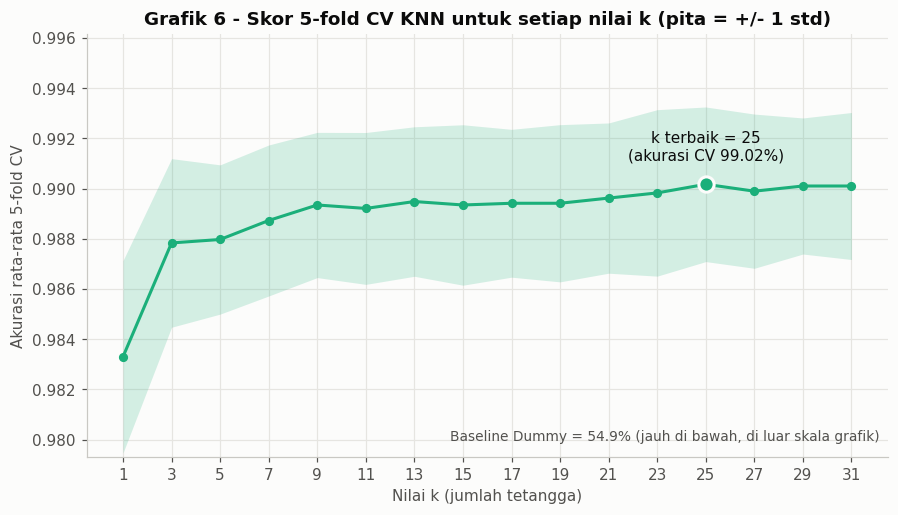

In [ ]:
# 4.3 Grafik 6: skor CV untuk tiap nilai k
k_terbaik_tmp = int(hasil_cv.loc[hasil_cv["akurasi_cv_rata2"].idxmax(), "k"])
skor_terbaik_tmp = hasil_cv["akurasi_cv_rata2"].max()
HIJAU = "#1baf7a"

fig, ax = plt.subplots(figsize=(9.4, 5))
ax.fill_between(hasil_cv["k"], hasil_cv["akurasi_cv_rata2"] - hasil_cv["std"],
                hasil_cv["akurasi_cv_rata2"] + hasil_cv["std"], color=HIJAU, alpha=0.18, linewidth=0)
ax.plot(hasil_cv["k"], hasil_cv["akurasi_cv_rata2"], color=HIJAU, linewidth=2, marker="o", markersize=5)
ax.scatter([k_terbaik_tmp], [skor_terbaik_tmp], s=100, color=HIJAU, edgecolor=SURFACE, linewidth=2, zorder=5)
ax.annotate(f"k terbaik = {k_terbaik_tmp}\n(akurasi CV {skor_terbaik_tmp * 100:.2f}%)",
            xy=(k_terbaik_tmp, skor_terbaik_tmp), xytext=(0, 16), textcoords="offset points",
            ha="center", color=INK, fontsize=10)
ax.set_xticks(daftar_k)
ax.set_ylim(hasil_cv["akurasi_cv_rata2"].min() - 0.004, skor_terbaik_tmp + 0.006)
ax.set_xlabel("Nilai k (jumlah tetangga)")
ax.set_ylabel("Akurasi rata-rata 5-fold CV")
ax.set_title("Grafik 6 - Skor 5-fold CV KNN untuk setiap nilai k (pita = +/- 1 std)")
ax.text(0.99, 0.04, f"Baseline Dummy = {DUMMY_CV_MEAN * 100:.1f}% (jauh di bawah, di luar skala grafik)",
        transform=ax.transAxes, ha="right", color=INK2, fontsize=9)
plt.show()


#### 4.3 Isi dan interpretasi Grafik 6

**Isi grafik.** Sumbu X adalah nilai k (1 sampai 31, ganjil), sumbu Y adalah akurasi rata-rata 5-fold CV, garis hijau adalah skor rata-rata, dan pita hijau muda adalah ±1 standar deviasi. Titik besar menandai k terbaik.

**Interpretasi.**
1. **k = 1 paling rendah** (98,33%) dan pitanya paling lebar (std 0,38 poin). Ini sesuai teori: tetangga tunggal gampang tertipu butir yang nyasar.
2. **Skor naik cepat dari k = 1 ke k = 3** (98,78%), lalu **melandai** dan stabil di kisaran 98,92% sampai 99,02% untuk k = 9 sampai 31.
3. **Titik tertinggi di k = 25** (99,02%). Tapi lihat pitanya: lebarnya sekitar ±0,31 poin, sedangkan selisih skor antar k di rentang 9 sampai 31 hanya sekitar 0,10 poin. Jadi **selisih antar k di daerah datar itu tidak bermakna secara statistik**. Saya jujur saja: k = 25 dipilih karena rata-ratanya paling tinggi, tapi k lain di kisaran 9 sampai 31 hampir pasti memberi hasil setara.
4. Baseline Dummy ada di 54,9%, jauh di bawah semua titik di grafik ini.

### 4.4 Memilih k terbaik dan menyiapkan model final



In [ ]:
# 4.4 Pilih k terbaik dan siapkan model final (belum menyentuh data uji)
baris_terbaik = hasil_cv.loc[hasil_cv["akurasi_cv_rata2"].idxmax()]
K_TERBAIK = int(baris_terbaik["k"])

# K_TERBAIK = 5   # <- buka komentar ini kalau mau coba k lain (misal diminta dosen), lalu Run ulang sel di bawahnya
SKOR_CV_KNN = float(hasil_cv.loc[hasil_cv["k"] == K_TERBAIK, "akurasi_cv_rata2"].iloc[0])

print("5 nilai k dengan skor CV tertinggi:")
display(hasil_cv.sort_values("akurasi_cv_rata2", ascending=False).head(5).set_index("k"))
print(f"k yang dipakai = {K_TERBAIK} (akurasi CV {SKOR_CV_KNN:.4f})")

model_knn = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=K_TERBAIK))])
model_dummy = DummyClassifier(strategy="most_frequent")
print(model_knn)


5 nilai k dengan skor CV tertinggi:


,akurasi_cv_rata2,std
k,,
25,0.9902,0.0031
29,0.9901,0.0027
31,0.9901,0.0029
27,0.9899,0.0031
23,0.9898,0.0033


k yang dipakai = 25 (akurasi CV 0.9902)
Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=25))])


### 4.5 Keputusan saya (Tahap 4)

**Tahap 4**
- **Sel 4.1 (baseline):** `DummyClassifier(strategy="most_frequent")` dengan 5-fold CV. **Hasil:** akurasi CV **54,91%** (std 0,008 poin). Ini cocok dengan porsi Kelas 1 di data latih, karena Dummy cuma menebak Kelas 1 terus.
- **Sel 4.2 (tuning k):** 16 nilai k ganjil (1 sampai 31), masing-masing dinilai dengan 5-fold CV memakai `Pipeline(StandardScaler, KNN)`. **Hasil:** k = 1 hanya 98,33%; k = 3 sudah 98,78%; k = 9 sampai 31 berkisar 98,92% sampai 99,02%; **tertinggi k = 25 dengan 99,02%** (std 0,31 poin).
- **Sel 4.3 (Grafik 6):** garis skor CV vs k. Naik tajam dari k = 1 ke k = 3 lalu mendatar, dan pita ±1 std jauh lebih lebar daripada selisih antar k di bagian datar.
- **Sel 4.4:** memilih k terbaik, 5 besar berurutan: k = 25, 29, 31, 27, 23, lalu menyiapkan `model_knn` dan `model_dummy`.

**Keputusan yang saya ambil dan alasannya**
1. **Model final: `Pipeline(StandardScaler → KNeighborsClassifier(n_neighbors=25))`**, dengan pengaturan lain bawaan scikit-learn (bobot tetangga seragam, jarak Euclidean). Scaling ada **di dalam pipeline** supaya tidak bocor.
2. **Nilai k = 25**, karena rata-rata akurasi CV-nya tertinggi (99,02%). Saya sadar selisihnya dengan k lain di kisaran 9 sampai 31 sangat kecil dan tidak bermakna secara statistik, jadi pilihan ini **tidak sensitif**. Pilihan k yang cukup besar juga aman: lebih tahan terhadap outlier daripada k kecil, dan tidak ada tanda k = 25 terlalu besar karena skornya tidak turun.
3. **Kenapa tidak k = 1 atau 3?** Skor CV-nya lebih rendah (98,33% dan 98,78%) dan k = 1 paling goyang. Itu pola khas overfitting terhadap butir yang nyasar.
4. **Baseline = 54,91%.** KNN pada k terbaik (99,02%) unggul sekitar **44,1 poin persentase** di CV. Keunggulan sebesar ini jauh melebihi standar deviasi mana pun, jadi jelas bukan kebetulan.
5. **Soal `SEED`:** KNN tidak punya komponen acak, jadi tidak ada argumen `random_state` di modelnya. SEED = 636 tetap dipakai di pembagian data dan `StratifiedKFold`, sehingga seluruh hasil bisa diulang persis.
6. **Tips presentasi:** kalau dosen minta mengganti k, buka komentar baris `# K_TERBAIK = 5` di sel 4.4 (ganti angkanya), lalu **Run** sel 4.4 dan semua sel di bawahnya. Seluruh tabel, grafik, dan hasil perhitungan di Tahap 5 akan ikut berubah. Catatan: angka di dalam sel teks "Keputusan saya" dan interpretasi adalah hasil untuk k yang terpilih saat ini, jadi tidak otomatis berubah; cukup dijelaskan lisan bahwa itu hasil untuk k = 25.

---
# 5. Evaluasi dan Interpretasi


### 5.1 Melatih model final dan menguji satu kali di data uji



In [ ]:
# 5.1 Latih model final di seluruh data latih, lalu uji SATU KALI di data uji
model_dummy.fit(X_train, y_train)
model_knn.fit(X_train, y_train)

pred = {
    "Baseline (Dummy)":      {"latih": model_dummy.predict(X_train), "uji": model_dummy.predict(X_test)},
    f"KNN (k={K_TERBAIK})":  {"latih": model_knn.predict(X_train),   "uji": model_knn.predict(X_test)},
}
NAMA_KNN = f"KNN (k={K_TERBAIK})"

baris = {}
for nama, p in pred.items():
    baris[nama] = {
        "akurasi": accuracy_score(y_test, p["uji"]),
        "presisi": precision_score(y_test, p["uji"], pos_label=1, zero_division=0),
        "recall": recall_score(y_test, p["uji"], pos_label=1, zero_division=0),
        "f1": f1_score(y_test, p["uji"], pos_label=1, zero_division=0),
    }
metrik_uji = pd.DataFrame(baris).T
display(metrik_uji)


,akurasi,presisi,recall,f1
Baseline (Dummy),0.5491,0.5491,1.0000,0.7089
KNN (k=25),0.9876,0.9865,0.9910,0.9888


### 5.2 Grafik 7: Confusion matrix di data uji



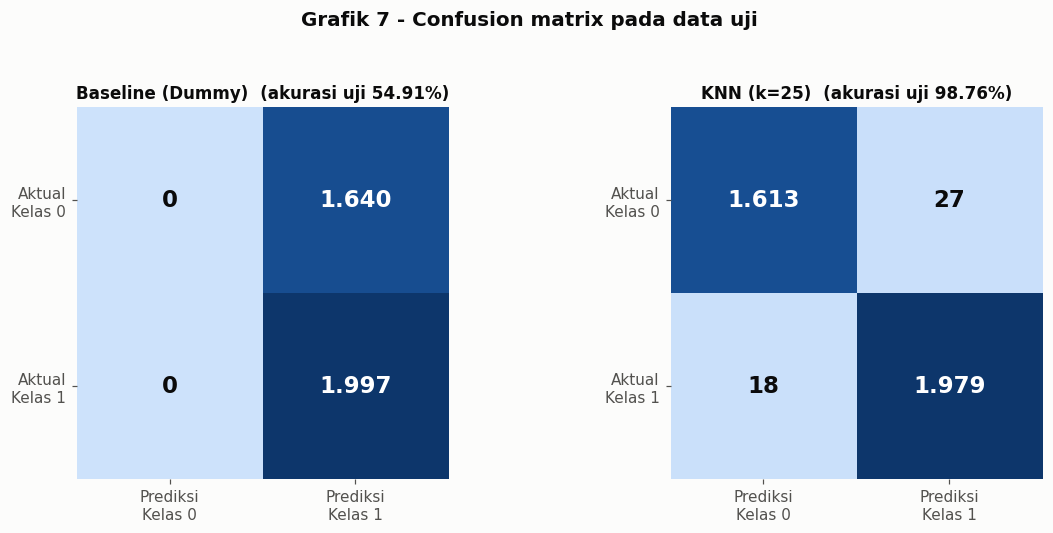

In [ ]:
# 5.2 Grafik 7: confusion matrix di data uji (baseline vs KNN)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.9))
for ax, (nama, p) in zip(axes, pred.items()):
    cm = confusion_matrix(y_test, p["uji"], labels=[0, 1])
    ax.imshow(cm, cmap=CMAP_SEQ, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=15,
                    fontweight="bold", color="white" if cm[i, j] > cm.max() * 0.5 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Prediksi\nKelas 0", "Prediksi\nKelas 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Aktual\nKelas 0", "Aktual\nKelas 1"])
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(f"{nama}  (akurasi uji {accuracy_score(y_test, p['uji']) * 100:.2f}%)", fontsize=11)
fig.suptitle("Grafik 7 - Confusion matrix pada data uji", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


#### 5.2 interpretasi Grafik 7

**Isi grafik.**
- **Kiri (Baseline Dummy):** kolom "Prediksi Kelas 0" isinya nol semua, karena Dummy selalu menebak Kelas 1. Hasilnya: 1.997 butir Kelas 1 tertebak benar, tetapi **1.640 butir Kelas 0 semuanya salah** (disangka Kelas 1) dan tidak ada satu pun butir Kelas 0 yang berhasil dikenali.
- **Kanan (KNN k = 25):** 1.613 butir Kelas 0 tertebak benar (**TN**), 1.979 butir Kelas 1 tertebak benar (**TP**), **27 butir Kelas 0 salah disangka Kelas 1 (FP)**, dan **18 butir Kelas 1 salah disangka Kelas 0 (FN)**.

**Interpretasi.**
1. Dummy tampak "bagus" di recall (100%), tapi itu **semu**: dia bilang semua butir Kelas 1, jadi tentu semua Kelas 1 "ketemu", sementara Kelas 0 tidak terdeteksi sama sekali. Inilah kenapa akurasi dan F1 kelas positif saja bisa menipu, dan confusion matrix membuka kedoknya.
2. KNN benar pada 3.592 dari 3.637 butir uji; **hanya 45 butir yang salah** (1,24% atau sekitar 12 dari tiap 1.000 butir).
3. Kesalahannya **cukup seimbang** antara dua jenis (27 FP dan 18 FN), jadi model tidak berat sebelah ke salah satu kelas. Di sel 5.5 saya lihat butir macam apa yang salah ditebak.

### 5.3 Perhitungan manual metrik dari angka confusion matrix KNN

In [ ]:
# 5.3 Perhitungan manual metrik dari angka confusion matrix KNN
cm_knn = confusion_matrix(y_test, pred[NAMA_KNN]["uji"], labels=[0, 1])
TN, FP, FN, TP = cm_knn.ravel()
total = TP + TN + FP + FN

akurasi_m = (TP + TN) / total
presisi_m = TP / (TP + FP)
recall_m = TP / (TP + FN)
f1_m = 2 * presisi_m * recall_m / (presisi_m + recall_m)

print(f"TN = {TN} | FP = {FP} | FN = {FN} | TP = {TP} | total data uji = {total}")
print()
print(f"Akurasi  = (TP + TN) / total        = ({TP} + {TN}) / {total} = {akurasi_m:.4f}")
print(f"Presisi  = TP / (TP + FP)           = {TP} / ({TP} + {FP}) = {presisi_m:.4f}")
print(f"Recall   = TP / (TP + FN)           = {TP} / ({TP} + {FN}) = {recall_m:.4f}")
print(f"F1       = 2 x P x R / (P + R)      = 2 x {presisi_m:.4f} x {recall_m:.4f} / ({presisi_m:.4f} + {recall_m:.4f}) = {f1_m:.4f}")

# cek silang dengan hasil sklearn
cocok = np.allclose([akurasi_m, presisi_m, recall_m, f1_m], metrik_uji.loc[NAMA_KNN, ["akurasi", "presisi", "recall", "f1"]].values)
print("\nSama dengan hitungan sklearn? ", cocok)


TN = 1613 | FP = 27 | FN = 18 | TP = 1979 | total data uji = 3637

Akurasi  = (TP + TN) / total        = (1979 + 1613) / 3637 = 0.9876
Presisi  = TP / (TP + FP)           = 1979 / (1979 + 27) = 0.9865
Recall   = TP / (TP + FN)           = 1979 / (1979 + 18) = 0.9910
F1       = 2 x P x R / (P + R)      = 2 x 0.9865 x 0.9910 / (0.9865 + 0.9910) = 0.9888

Sama dengan hitungan sklearn?  True


#### 5.3 Hasil perhitungan manual

**Contoh perhitungan lengkap untuk metrik presisi (angka dari confusion matrix KNN):**

Presisi = TP / (TP + FP) = 1.979 / (1.979 + 27) = 1.979 / 2.006 = **0,9865**

Artinya: dari 2.006 butir yang ditebak Kelas 1 oleh model, 1.979 butir benar-benar Kelas 1. Dengan cara yang sama: akurasi = (1.979 + 1.613) / 3.637 = **0,9876**, recall = 1.979 / (1.979 + 18) = **0,9910**, dan F1 = **0,9888**. Semuanya cocok dengan hitungan `scikit-learn`.

### 5.4 Tabel perbandingan model vs baseline dan pengecekan overfitting



In [ ]:
# 5.4 Tabel perbandingan model vs baseline + cek overfitting (skor latih vs uji)
cv_mean = {"Baseline (Dummy)": DUMMY_CV_MEAN, NAMA_KNN: SKOR_CV_KNN}
tabel_banding = pd.DataFrame({
    "akurasi_cv_5fold": cv_mean,
    "akurasi_latih": {n: accuracy_score(y_train, p["latih"]) for n, p in pred.items()},
    "akurasi_uji": {n: accuracy_score(y_test, p["uji"]) for n, p in pred.items()},
    "presisi_uji": metrik_uji["presisi"],
    "recall_uji": metrik_uji["recall"],
    "f1_uji": metrik_uji["f1"],
})
tabel_banding["selisih_latih_uji"] = tabel_banding["akurasi_latih"] - tabel_banding["akurasi_uji"]
display(tabel_banding)


,akurasi_cv_5fold,akurasi_latih,akurasi_uji,presisi_uji,recall_uji,f1_uji,selisih_latih_uji
Baseline (Dummy),0.5491,0.5491,0.5491,0.5491,1.0000,0.7089,0.0000
KNN (k=25),0.9902,0.9907,0.9876,0.9865,0.9910,0.9888,0.0030


#### 5.4 Interpretasi tabel perbandingan dan cek overfitting

**Interpretasi.**
1. **Overfitting? Tidak.** Akurasi latih KNN 99,07% dan akurasi uji 98,76%, selisihnya hanya **0,30 poin persentase**. Skor CV (99,02%), skor latih, dan skor uji ketiganya nyaris sama, dan perbedaan sekecil itu masih di dalam standar deviasi CV (sekitar 0,31 poin). Kalau modelnya overfit, skor latih akan jauh melampaui skor uji.
2. **Skor uji konsisten dengan skor CV.** Itu artinya pemilihan k lewat CV memang bisa diandalkan dan tidak ada kebocoran dari data uji.
3. **Baseline:** akurasinya 54,91% di data latih, CV, **dan** uji (selisih nol), karena dia memang tidak belajar apa-apa selain "kelas mayoritas".
4. **KNN vs baseline di data uji:** akurasi 98,76% berbanding 54,91% (unggul **43,85 poin persentase**); F1 98,88% berbanding 70,89%; presisi 98,65% berbanding 54,91%. Recall baseline lebih tinggi (100%) tapi itu semu seperti dijelaskan di Grafik 7.

### 5.5 Analisis kesalahan: butir seperti apa yang salah ditebak?



In [ ]:
# 5.5 Analisis kesalahan: butir yang salah ditebak itu "tipe" yang seperti apa?
fitur_kunci = ["MinorAxisLength", "AspectRation", "Roundness", "Area"]
p_uji = pred[NAMA_KNN]["uji"]

data_uji = X_test.copy()
data_uji["aktual"] = y_test.values
data_uji["prediksi"] = p_uji
fp_idx = (data_uji["aktual"] == 0) & (data_uji["prediksi"] == 1)
fn_idx = (data_uji["aktual"] == 1) & (data_uji["prediksi"] == 0)

profil = pd.DataFrame({
    "Rata-rata Kelas 0 (data latih)": X_train.loc[y_train == 0, fitur_kunci].mean(),
    "Rata-rata Kelas 1 (data latih)": X_train.loc[y_train == 1, fitur_kunci].mean(),
    f"Salah tebak: aktual 0, prediksi 1 (FP, n={int(fp_idx.sum())})": data_uji.loc[fp_idx, fitur_kunci].mean(),
    f"Salah tebak: aktual 1, prediksi 0 (FN, n={int(fn_idx.sum())})": data_uji.loc[fn_idx, fitur_kunci].mean(),
}).T
display(profil)


,MinorAxisLength,AspectRation,Roundness,Area
Rata-rata Kelas 0 (data latih),70.0152,2.1991,0.7699,8361.1811
Rata-rata Kelas 1 (data latih),51.4478,2.9270,0.6572,5952.1368
"Salah tebak: aktual 0, prediksi 1 (FP, n=27)",56.6305,2.5736,0.6968,6389.2222
"Salah tebak: aktual 1, prediksi 0 (FN, n=18)",59.7271,2.3271,0.7377,6389.9444


#### 5.5 Interpretasi analisis kesalahan

**Isi tabel.** Empat baris dibandingkan pada fitur `MinorAxisLength`, `AspectRation`, `Roundness`, dan `Area`:
- Rata-rata **Kelas 0 normal**: lebar 70,0, rasio 2,20, kebulatan 0,770.
- Rata-rata **Kelas 1 normal**: lebar 51,4, rasio 2,93, kebulatan 0,657.
- Butir **FP** (aslinya Kelas 0): lebar 56,6, rasio 2,57, kebulatan 0,697.
- Butir **FN** (aslinya Kelas 1): lebar 59,7, rasio 2,33, kebulatan 0,738.

**Interpretasi.**
1. **Butir yang salah ternyata "tipe perbatasan".** Butir FP (aslinya Kelas 0) lebarnya cuma 56,6, jauh lebih sempit daripada Kelas 0 normal (70,0) dan sudah condong ke ukuran Kelas 1. Sebaliknya butir FN (aslinya Kelas 1) lebarnya 59,7, jauh lebih lebar daripada Kelas 1 normal (51,4) dan rasionya (2,33) lebih mirip Kelas 0.
2. Ini **persis sesuai prediksi dari Grafik 5**: kesalahan menumpuk di zona campur yang sempit di tengah, di mana dua kelas memang tumpang tindih. Jadi model tidak "bodoh"; butir-butir ini secara ukuran memang mirip kelas lain.
3. **Dugaan saya, kesalahan tersisa sulit dihilangkan** hanya dengan mengganti k atau algoritma, karena sumbernya adalah **kemiripan fisik antarkelas** pada fitur yang tersedia (ini dugaan, belum saya uji dengan algoritma lain). Menambah fitur baru yang lebih membedakan (misalnya tekstur atau warna) kemungkinan lebih menolong daripada tuning lanjutan.

### 5.6 Keputusan saya (Tahap 5)

**Tahap 5**
- **Sel 5.1:** melatih `model_dummy` dan `model_knn` (k = 25) di seluruh data latih, menguji **satu kali** di data uji. **Hasil (data uji):** KNN akurasi 98,76%, presisi 98,65%, recall 99,10%, F1 98,88%; baseline akurasi 54,91%, presisi 54,91%, recall 100,00%, F1 70,89%.
- **Sel 5.2 (Grafik 7):** confusion matrix KNN: **TN = 1.613, FP = 27, FN = 18, TP = 1.979**. Confusion matrix baseline: semua butir ditebak Kelas 1, jadi tidak ada satu pun Kelas 0 yang benar.
- **Sel 5.3:** perhitungan manual dari angka confusion matrix, misalnya presisi = 1.979 / (1.979 + 27) = 0,9865, cocok dengan `scikit-learn`.
- **Sel 5.4:** tabel perbandingan. **Hasil:** akurasi latih 99,07% vs uji 98,76% (selisih 0,30 poin), CV 99,02%.
- **Sel 5.5:** analisis kesalahan: 27 FP dan 18 FN. Rata-rata fitur butir yang salah jatuh **di antara** rata-rata kedua kelas.

**Keputusan yang saya ambil dan alasannya**
1. **Model KNN (k = 25) dinyatakan berhasil mengalahkan baseline dengan sangat jelas**: akurasi uji 98,76% vs 54,91%, F1 98,88% vs 70,89%.
2. **Tidak ada overfitting**, karena selisih skor latih dan uji hanya 0,30 poin dan skor CV (99,02%) hampir sama dengan skor uji (98,76%).
3. **Kualitas kedua kelas seimbang:** presisi 98,65% dan recall 99,10% sama-sama tinggi, dan jumlah kesalahan antar jenis seimbang (27 FP, 18 FN). Tidak perlu mengatur ulang ambang keputusan.
4. **Sisa kesalahan (45 butir) berasal dari butir "perbatasan"** yang secara ukuran memang mirip kelas lain (sel 5.5), jadi saya menduga mengutak-atik algoritma tidak akan banyak membantu (dugaan ini belum saya uji). Hasilnya sudah mendekati batas yang bisa dicapai dari fitur yang ada.
5. **Baseline tidak boleh dibaca dari recall-nya** (100%), karena itu semu: dia tidak mengenali satu pun butir Kelas 0.
6. **Data uji sudah dipakai sekali** dan tidak dipakai lagi untuk mengubah model, sehingga angka-angka ini adalah estimasi yang jujur.

---
# 6. Kesimpulan


### 6.1 Apakah model layak dipakai dibanding baseline? Model mana yang dipilih?

**Jawaban: ya, layak.** Model yang saya pilih adalah **KNN dengan k = 25 (didahului `StandardScaler` dalam satu Pipeline)**. Alasannya (semua pakai angka dari data uji):

1. **Akurasinya jauh melampaui baseline:** 98,76% vs 54,91%, unggul **43,85 poin persentase**. Dari 3.637 butir uji, KNN hanya salah 45 butir, sedangkan baseline salah 1.640 butir (semua Kelas 0).
2. **KNN mengenali kedua kelas, baseline hanya satu.** Dari 1.640 butir Kelas 0, KNN benar 1.613 (98,35%); baseline benar 0 (0,00%). Dari 1.997 butir Kelas 1, KNN benar 1.979 (99,10%). F1 KNN 98,88% lawan 70,89%.
3. **Tidak overfitting dan hasilnya konsisten:** akurasi latih 99,07%, CV 99,02%, uji 98,76%. Selisih latih dan uji hanya 0,30 poin.

**Alasan memilih KNN dengan k = 25:** skor CV-nya tertinggi di antara 16 kandidat k, dan di data uji kualitasnya terbukti (angka di atas). Saya tegaskan lagi bahwa selisih dengan k lain di kisaran 9 sampai 31 tidak bermakna, jadi yang paling penting adalah **menghindari k terlalu kecil** (k = 1 hanya 98,33% di CV).

### 6.2 Rekomendasi tindakan bagi pengguna

Untuk pengelola penggilingan, pengepul, atau petugas QC, rekomendasi saya:

1. **Pakai sebagai penyaring awal, bukan hakim akhir.** Model ini bisa memilah butir secara otomatis dengan kesalahan sekitar 12 per 1.000 butir. Untuk lot yang bernilai tinggi atau menjadi sengketa, tetap sediakan pemeriksaan manual atas sampel.
2. **Kirim butir "meragukan" ke pemeriksaan manual.** Kesalahan model menumpuk pada butir perbatasan (lihat 5.5). Sebagai pengembangan lanjutan, KNN bisa dimintai tingkat keyakinan (misalnya lewat `predict_proba`, yaitu proporsi suara tetangga). Butir dengan suara tetangga yang hampir terbelah dua dikirim ke pemeriksa manusia.
3. **Standarkan cara memotret.** Semua fitur diukur dalam piksel, jadi model hanya sahih bila kamera, jarak, dan pencahayaan sama dengan data latih. Kalau kondisi berubah, ukuran piksel ikut berubah.
4. **Pantau secara berkala.** Ambil sampel acak dari tiap lot, periksa manual, dan bandingkan dengan tebakan model. Kalau akurasi di lapangan turun jauh di bawah angka uji (98,8%), latih ulang modelnya.
5. **Tentukan kesalahan mana yang lebih mahal.** Saat ini FP (27) dan FN (18) hampir seimbang. Kalau salah satunya lebih merugikan (misalnya lot tercampur jenis lain yang lolos), ambang keputusan bisa digeser agar kesalahan itu ditekan.

### 6.3 Keterbatasan dan saran perbaikan

**Keterbatasan**
1. **Datanya mudah dipisahkan.** Bahkan satu aturan sederhana pada satu fitur (`MinorAxisLength`) sudah menghasilkan akurasi CV 98,50% (sel 3.4). Jadi akurasi ~99% tidak berarti KNN "luar biasa"; selisih antar algoritma yang bagus kemungkinan kecil. Yang saya buktikan adalah bahwa prosesnya sehat (tidak bocor, tidak overfit).
2. **Data uji berasal dari dataset yang sama** (pembagian acak). Di lapangan, kamera, pencahayaan, kondisi butir (patah, basah), atau jenis beras lokal yang berbeda bisa menurunkan performa. Angka ini belum membuktikan kinerja di kondisi nyata.
3. **Hanya dua kelas, dan arti label 0/1 belum saya verifikasi** dari sumber (lihat catatan 1.2). Satuan fitur juga asumsi (piksel).
4. **Fitur redundan.** Beberapa fitur turunan dari fitur lain (sel 3.6). Untuk akurasi di sini tidak berpengaruh (sel 3.7), tapi tetap membuat model tidak seefisien mungkin.
5. **Keterbatasan KNN:** harus menyimpan seluruh 14.548 butir data latih dan menghitung jarak tiap prediksi, jadi bisa lambat kalau datanya jauh lebih besar; hanya parameter k yang saya tala, sedangkan bobot tetangga dan jenis jarak memakai bawaan.
6. **Tidak ada perbandingan dengan algoritma lain**, sesuai instruksi memakai satu algoritma.

**Saran perbaikan**
- Bandingkan dengan **SVM atau Naive Bayes** sebagai pembanding (nilai tambah di soal) untuk melihat apakah ada yang lebih baik atau lebih ringan.
- **Uji pada foto baru** dari kamera dan lokasi berbeda, idealnya dengan jenis beras lokal Indonesia.
- Tambahkan **fitur baru** yang membedakan butir perbatasan (warna atau tekstur), karena sisa kesalahan berasal dari kemiripan ukuran.
- Coba **PCA atau seleksi fitur** untuk meringkas fitur kembar, dan coba `weights="distance"` atau jarak lain.
- Gunakan **repeated cross-validation** supaya pemilihan k lebih mantap, mengingat selisih antar k sangat kecil.

### 6.4 Keputusan saya (Tahap 6)

**Tahap 6**
- **Model terpilih:** KNN (k = 25) dengan `StandardScaler` dalam satu `Pipeline`, **layak dipakai** dibanding baseline.
- **Dua alasan utama berbasis angka:** (1) akurasi uji **98,76%** vs baseline **54,91%** (selisih 43,85 poin), F1 **98,88%** vs 70,89%; (2) selisih akurasi latih dan uji hanya **0,30 poin** (CV 99,02%), jadi tidak overfitting.

**Keputusan yang saya ambil dan alasannya**
1. **Rekomendasi ke pengguna:** pakai sebagai **penyaring awal** otomatis, siapkan pemeriksaan manual untuk butir perbatasan dan untuk sampel pengawasan, standarkan cara memotret, dan pantau akurasi di lapangan (6.2).
2. **Saya jujur soal batasannya:** masalahnya mudah dipisahkan (satu fitur saja sudah 98,5%), data uji berasal dari sumber yang sama, dan arti label 0/1 serta lisensi data masih perlu saya lengkapi dari halaman sumber (6.3 dan 1.2).
3. **Langkah lanjutan yang paling bernilai:** uji pada foto baru dari kamera berbeda dan bandingkan dengan SVM atau Naive Bayes.

